# 05: Meta-Labeling and Statistical Significance

Two final layers, one that tries to improve the strategy and one that
keeps me honest about whether anything improved at all.

**Meta-labeling** (Lopez de Prado). The walk-forward rule decides when a
trade triggers; a gradient-boosted classifier then estimates, from
conditions known at decision time, the probability that this particular
trigger wins. I train it on the development trade history with purged
cross-validation: chronological folds, training trades whose lifetimes
overlap a test fold (plus a 60-day embargo) are removed, because
overlapping trades share market state and ordinary K-fold would leak.

**Significance statistics** (Bailey and Lopez de Prado). I tuned over a
grid and kept the best cell, and the maximum of N noisy Sharpes is
biased upward even when nothing works. The deflated Sharpe ratio asks:
what is the probability the result beats what the luckiest of my N
trials would show by chance? I count every configuration I evaluated, so
N is the true trial count, not a guess.

In [1]:
# Setup: make src importable and load shared inputs
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks"
                       else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from src import (universe, cointegration, kalman_hedge, regime_detector,
                 signal_generator, backtest, report, config)

prices = universe.download_universe()
splits = universe.load_splits()
stocks = prices[universe.stock_columns(prices)]
vix = prices[config.VIX_TICKER]
train = universe.get_split(stocks, "train")
print("data:", prices.shape, "| splits:", splits)

data: (1257, 41) | splits: {'train': ['2021-06-11', '2024-06-10'], 'validation': ['2024-06-11', '2025-06-11'], 'test': ['2025-06-12', '2026-06-11']}


dev trades: 131, base win rate 72.5%
purged-CV fold AUCs: [0.773, 0.556, 0.533, 0.68, 0.524]
mean AUC: 0.613  (0.5 = no skill)


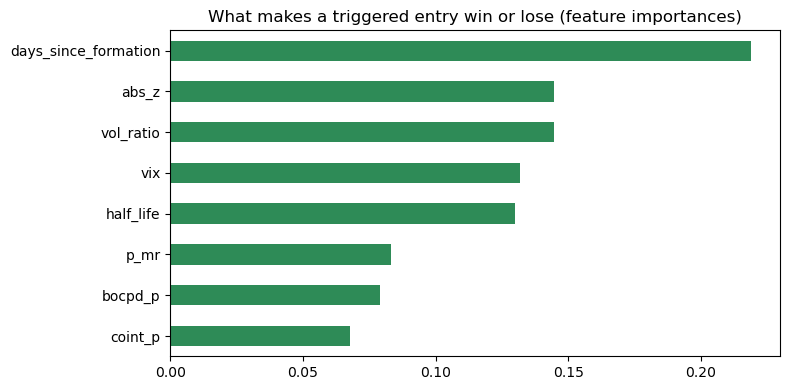

In [2]:
from src import meta_label, stats_validation

meta = json.loads((config.RESULTS_DIR / "meta_cv.json").read_text())
print(f"dev trades: {meta['n_trades']}, base win rate {meta['base_win_rate']:.1%}")
print(f"purged-CV fold AUCs: {[round(a,3) for a in meta['fold_aucs']]}")
print(f"mean AUC: {meta['mean_auc']:.3f}  (0.5 = no skill)")

imp = pd.Series(meta["importances"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
imp.plot(kind="barh", ax=ax, color="seagreen")
ax.set_title("What makes a triggered entry win or lose (feature importances)")
plt.tight_layout(); plt.show()

## Reading the AUC honestly

An AUC modestly above 0.5 under purged CV means the entry conditions
carry some information about trade outcomes; an AUC at or below 0.5
means the meta-model is noise and its test-year filtering should be
expected to do nothing. Either way the test-year ablation below shows
exactly what the filter did out of sample, because I ran the frozen test
year both with and without it.

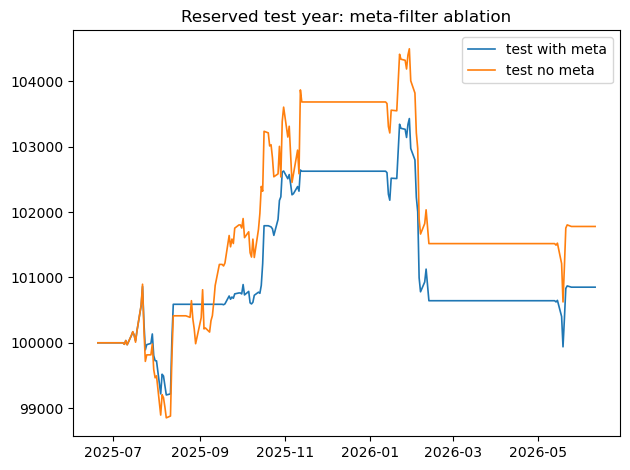

,total_return,sharpe,max_drawdown,n_trades,win_rate,profit_factor
test with meta,0.009,0.352,-0.034,12.0,0.667,1.198
test no meta,0.018,0.505,-0.037,14.0,0.643,1.333


In [3]:
rows = {}
for tag, eqf, trf in [
    ("test with meta", "wf_equity_test.csv", "wf_trades_test.csv"),
    ("test no meta", "wf_equity_test_nometa.csv", "wf_trades_test_nometa.csv")]:
    eq = pd.read_csv(config.RESULTS_DIR / eqf, index_col=0, parse_dates=True)["equity"]
    tr = pd.read_csv(config.RESULTS_DIR / trf)
    m = backtest.compute_metrics(eq, tr)
    rows[tag] = {k: m[k] for k in ("total_return","sharpe","max_drawdown",
                                   "n_trades","win_rate","profit_factor")}
    plt.plot(eq, label=tag, lw=1.2)
plt.legend(); plt.title("Reserved test year: meta-filter ablation")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).T.round(3))

## Signal or luck: PSR, DSR, bootstrap

The table below is, to me, the most important output of the entire
project. The deflated Sharpe benchmark ("E[max SR | luck]") is what the
best of my tuning trials would show if every configuration were pure
noise. Any Sharpe that does not clearly beat that number, with a
bootstrap interval that excludes zero, is not evidence of edge, no
matter how good the equity curve looks.

In [4]:
sig = json.loads((config.RESULTS_DIR / "significance.json").read_text())
df = pd.DataFrame(sig).T
df["ci_90"] = df["bootstrap_90ci"].apply(
    lambda d: f"({d['lo']:+.2f}, {d['hi']:+.2f})")
display(df[["sharpe_annual","psr","dsr","expected_max_sharpe_annual","ci_90"]]
        .astype({"sharpe_annual":float,"psr":float,"dsr":float,
                 "expected_max_sharpe_annual":float}).round(2))

params_v2 = json.loads(config.TUNED_V2_JSON.read_text())
print("\nthe full tuning surface (what N trials actually looked like):")
print(pd.Series(params_v2["scores"]).round(2).to_string())

,sharpe_annual,psr,dsr,expected_max_sharpe_annual,ci_90
development,0.75,0.97,0.39,0.85,"(+0.01, +1.46)"
test,0.35,0.63,0.31,0.85,"(-1.48, +2.41)"
test_nometa,0.51,0.69,0.36,0.85,"(-1.07, +1.91)"



the full tuning surface (what N trials actually looked like):
1e-05/rolling    0.27
1e-05/zero      -0.87
1e-05/ou        -0.67
1e-04/rolling    0.75
1e-04/zero      -0.93
1e-04/ou        -0.79
1e-03/rolling   -0.40
1e-03/zero      -0.21
1e-03/ou        -0.42
